# Base paper vs proposed work

In [1]:
import os, sys, json
ROOT = os.getcwd()
while not os.path.exists(os.path.join(ROOT, "src", "config.py")):
    parent = os.path.dirname(ROOT)
    if parent == ROOT:
        raise RuntimeError("Project root (folder containing src/) not found")
    ROOT = parent
FIG = os.path.join(ROOT, "comparison_figures")
os.makedirs(FIG, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

def load(folder, name):
    with open(os.path.join(ROOT, folder, name)) as f:
        return json.load(f)

base_t, prop_t = load("base_paper", "timing.json"), load("proposed_work", "timing.json")
base_r, prop_r = load("base_paper", "results.json"), load("proposed_work", "results.json")

BASE_COLOR, PROP_COLOR, INK, MUTED = "#eb6834", "#2a78d6", "#0b0b0b", "#898781"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": INK,
                     "ytick.color": INK, "axes.grid": True, "grid.color": "#e5e4df",
                     "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10})

print("Base paper run    :", base_t["started"], "->", base_t["finished"], f"({base_t['total_seconds']:.2f} s)")
print("Proposed work run :", prop_t["started"], "->", prop_t["finished"], f"({prop_t['total_seconds']:.2f} s)")

Base paper run    : 2026-10-11 16:26:39 -> 2026-10-11 16:26:50 (11.60 s)
Proposed work run : 2026-10-11 16:26:52 -> 2026-10-11 16:27:03 (11.50 s)


## Method comparison

In [2]:
method = pd.DataFrame([
    ["1. Classical GCI model", "Vasicek PD(z), p0 = 0.25, rho = 0.027, LGD = $1000", "Same", "Same"],
    ["2. Quantum encoding", "PD(z) ~ sin^2(alpha z + beta), register-adapted angles", "Same", "Same"],
    ["3. Circuit design", "Ry + CNOT loader, Ry / CRy asset qubit", "Same", "Same"],
    ["4. Classical training", "Parameter shift + Adam", "Same", "Same"],
    ["5. Transpilation", "Qiskit preset pass manager, SABRE", "Same", "Same"],
    ["6. Calibration", "Manual coarse-to-fine grid sweep, one angle at a time",
     "Automated: Bayesian optimisation -> Bayesian optimisation -> SPSA -> verify", "Add-on"],
    ["   Readout mitigation", "None (stated in the paper)", "Assignment matrix + NNLS correction", "Add-on"],
    ["7. Execution", "Raw counts, repeated runs", "Readout-corrected counts, repeated runs", "Add-on"],
    ["7b. Zero-noise extrapolation", "None", "Noise x1, x3, x5 (circuit folding), extrapolate to 0", "Add-on"],
    ["8. Post-processing", "PD, loss CDF, expected loss, VaR", "Same", "Same"],
    ["9. Validation", "Hellinger fidelity reported", "Fidelity gate: >= 0.97 ACCEPT, else RE-CALIBRATE", "Add-on"],
    ["Drift handling", "No detection; manual sweep repeated", "Automatic detection + recalibration loop", "Add-on"],
], columns=["Stage", "Base paper", "Proposed work", "Change"])
method

,Stage,Base paper,Proposed work,Change
0,1. Classical GCI model,"Vasicek PD(z), p0 = 0.25, rho = 0.027, LGD = $1000",Same,Same
1,2. Quantum encoding,"PD(z) ~ sin^2(alpha z + beta), register-adapted angles",Same,Same
2,3. Circuit design,"Ry + CNOT loader, Ry / CRy asset qubit",Same,Same
3,4. Classical training,Parameter shift + Adam,Same,Same
4,5. Transpilation,"Qiskit preset pass manager, SABRE",Same,Same
5,6. Calibration,"Manual coarse-to-fine grid sweep, one angle at a time",Automated: Bayesian optimisation -> Bayesian optimisation -> SPSA -> verify,Add-on
6,Readout mitigation,None (stated in the paper),Assignment matrix + NNLS correction,Add-on
7,7. Execution,"Raw counts, repeated runs","Readout-corrected counts, repeated runs",Add-on
8,7b. Zero-noise extrapolation,None,"Noise x1, x3, x5 (circuit folding), extrapolate to 0",Add-on
9,8. Post-processing,"PD, loss CDF, expected loss, VaR",Same,Same


## Time stamps per stage

In [3]:
def by_stage(t):
    return {s["stage"].split(" - ")[0]: s for s in t["stages"]}

B, P = by_stage(base_t), by_stage(prop_t)
order = ["Stage 1", "Stage 2", "Stage 3", "Stage 4", "Stage 5", "Stage 6a", "Stage 6", "Stage 7", "Stage 7b",
         "Stage 8", "Stage 9", "Drift event"]
names = {"Stage 1": "Classical GCI model", "Stage 2": "Quantum encoding", "Stage 3": "Circuit design",
         "Stage 4": "Classical training", "Stage 5": "Transpilation",
         "Stage 6a": "Readout setup (add-on)", "Stage 6": "Calibration",
         "Stage 7": "Execution", "Stage 7b": "ZNE (add-on)", "Stage 8": "Post-processing",
         "Stage 9": "Validation", "Drift event": "Drift recovery"}

rows = []
for k in order:
    b, p = B.get(k), P.get(k)
    rows.append([f"{k} - {names[k]}",
                 b["start"] if b else "-", b["end"] if b else "-", b["seconds"] if b else 0.0,
                 p["start"] if p else "-", p["end"] if p else "-", p["seconds"] if p else 0.0])
timing = pd.DataFrame(rows, columns=["Stage", "Base start", "Base end", "Base (s)",
                                     "Proposed start", "Proposed end", "Proposed (s)"])
timing.loc[len(timing)] = ["TOTAL", base_t["started"][-8:], base_t["finished"][-8:], base_t["total_seconds"],
                           prop_t["started"][-8:], prop_t["finished"][-8:], prop_t["total_seconds"]]
timing.round(2)

,Stage,Base start,Base end,Base (s),Proposed start,Proposed end,Proposed (s)
0,Stage 1 - Classical GCI model,16:26:39.317,16:26:39.413,0.10,16:26:52.159,16:26:52.243,0.08
1,Stage 2 - Quantum encoding,16:26:39.417,16:26:39.418,0.00,16:26:52.247,16:26:52.247,0.00
2,Stage 3 - Circuit design,16:26:39.420,16:26:39.421,0.00,16:26:52.251,16:26:52.252,0.00
3,Stage 4 - Classical training,16:26:39.424,16:26:39.751,0.33,16:26:52.255,16:26:52.605,0.35
4,Stage 5 - Transpilation,16:26:39.755,16:26:39.785,0.03,16:26:52.609,16:26:52.636,0.03
5,Stage 6a - Readout setup (add-on),-,-,0.00,16:26:52.640,16:26:52.876,0.24
6,Stage 6 - Calibration,16:26:39.789,16:26:45.015,5.22,16:26:52.876,16:26:57.423,4.55
7,Stage 7 - Execution,16:26:45.018,16:26:45.980,0.96,16:26:57.431,16:26:58.368,0.94
8,Stage 7b - ZNE (add-on),-,-,0.00,16:26:58.374,16:26:58.948,0.57
9,Stage 8 - Post-processing,16:26:45.985,16:26:45.985,0.00,16:26:58.952,16:26:58.953,0.00


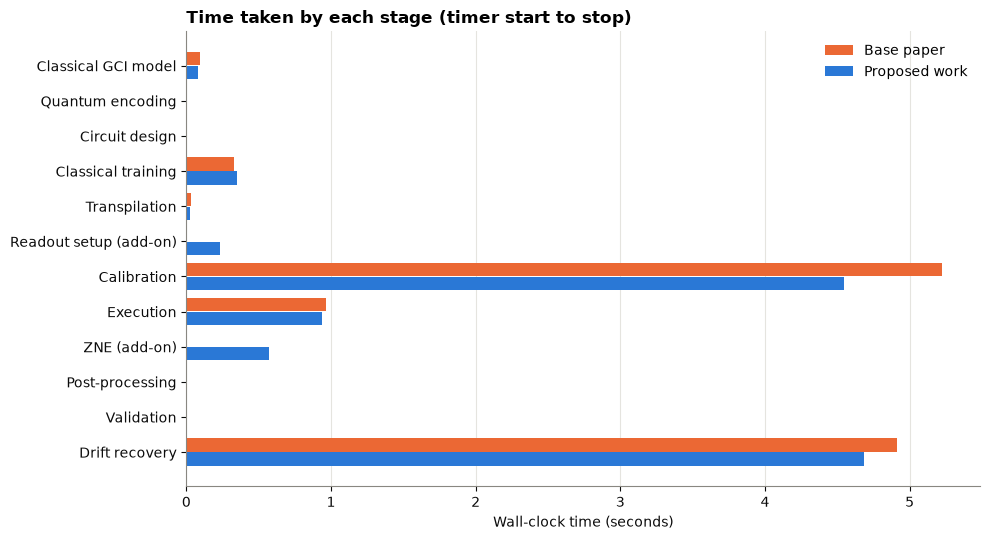

In [4]:
labels = [names[k] for k in order]
b_sec = [B[k]["seconds"] if k in B else 0.0 for k in order]
p_sec = [P[k]["seconds"] if k in P else 0.0 for k in order]

y = np.arange(len(order))
h = 0.38
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(y - h / 2 - 0.01, b_sec, h, color=BASE_COLOR, label="Base paper")
ax.barh(y + h / 2 + 0.01, p_sec, h, color=PROP_COLOR, label="Proposed work")
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlabel("Wall-clock time (seconds)")
ax.set_title("Time taken by each stage (timer start to stop)", loc="left", fontweight="bold")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper right", frameon=False)
plt.tight_layout()
plt.savefig(os.path.join(FIG, "time_per_stage.png"), dpi=150)
plt.show()

## Circuit runs and estimated chip time

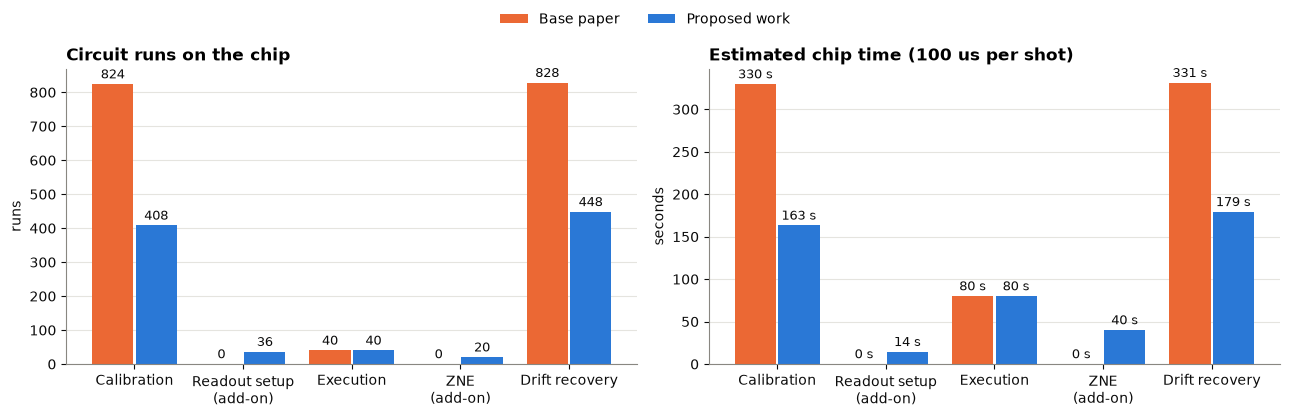

,Part,Base runs,Proposed runs,Base chip time (s),Proposed chip time (s),Runs saved
0,Calibration,824,408,329.6,163.2,50%
1,Readout setup (add-on),0,36,0.0,14.4,add-on
2,Execution,40,40,80.0,80.0,0%
3,ZNE (add-on),0,20,0.0,40.0,add-on
4,Drift recovery,828,448,331.2,179.2,46%


In [5]:
T_SHOT_US = 100   # assumed time per shot on a superconducting chip (reset + circuit + readout)

def runs_shots(t, keys):
    d = {s["stage"].split(" - ")[0]: s for s in t["stages"]}
    return sum(d[k]["circuit_runs"] for k in keys if k in d), sum(d[k]["shots"] for k in keys if k in d)

groups = {"Calibration": ["Stage 6"], "Readout setup (add-on)": ["Stage 6a"], "Execution": ["Stage 7"],
          "ZNE (add-on)": ["Stage 7b"], "Drift recovery": ["Drift event"]}
rows = []
for g, keys in groups.items():
    br, bs = runs_shots(base_t, keys)
    pr, ps = runs_shots(prop_t, keys)
    rows.append([g, br, pr, bs * T_SHOT_US / 1e6, ps * T_SHOT_US / 1e6])
cost = pd.DataFrame(rows, columns=["Part", "Base runs", "Proposed runs",
                                   "Base chip time (s)", "Proposed chip time (s)"])
cost["Runs saved"] = [f"{1 - p / b:.0%}" if b else "add-on" for b, p in zip(cost["Base runs"], cost["Proposed runs"])]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(len(cost))
w = 0.38
for ax, (bcol, pcol, title, unit) in zip(axes, [
        ("Base runs", "Proposed runs", "Circuit runs on the chip", "runs"),
        ("Base chip time (s)", "Proposed chip time (s)", f"Estimated chip time ({T_SHOT_US} us per shot)", "seconds")]):
    bb = ax.bar(x - w / 2 - 0.01, cost[bcol], w, color=BASE_COLOR, label="Base paper")
    pb = ax.bar(x + w / 2 + 0.01, cost[pcol], w, color=PROP_COLOR, label="Proposed work")
    for bars in (bb, pb):
        ax.bar_label(bars, fmt="%.0f" if unit == "runs" else "%.0f s", padding=2, fontsize=9, color=INK)
    ax.set_xticks(x)
    ax.set_xticklabels([p.replace(" (add-on)", "\n(add-on)") for p in cost["Part"]])
    ax.set_ylabel(unit)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.grid(axis="x", visible=False)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.savefig(os.path.join(FIG, "runs_and_chip_time.png"), dpi=150)
plt.show()
cost.round(1)

## Outcome

In [6]:
rows = []
for n in ("2q", "3q"):
    b, p = base_r["registers"][n], prop_r["registers"][n]
    rows += [
        [n, "Fidelity vs perfect chip", f"{b['fidelity_vs_ideal']:.4f}", f"{p['fidelity_vs_ideal']:.4f}"],
        [n, "Fidelity with ZNE", "-", f"{p.get('fidelity_zne', float('nan')):.4f}"],
        [n, "Decision", "no check", p["decision"]],
        [n, "Default probability (classical 0.25)", f"{b['p_default']:.4f}", f"{p['p_default']:.4f}"],
        [n, "Expected loss (classical $250)", f"${b['expected_loss']:.1f}", f"${p['expected_loss']:.1f}"],
        [n, "VaR 95%", f"${b['var95']:.0f}", f"${p['var95']:.0f}"],
        [n, "Calibration runs", b["calibration_runs"], p["calibration_runs"]],
        [n, "Drift: fidelity before -> after",
         f"{b['drift']['fidelity_before']:.3f} -> {b['drift']['fidelity_after']:.3f}",
         f"{p['drift']['fidelity_before']:.3f} -> {p['drift']['fidelity_after']:.3f}"],
        [n, "Drift: runs to recover", b["drift"]["recovery_runs"], p["drift"]["recovery_runs"]],
    ]
outcome = pd.DataFrame(rows, columns=["Register", "Metric", "Base paper", "Proposed work"])
outcome

,Register,Metric,Base paper,Proposed work
0,2q,Fidelity vs perfect chip,0.9002,0.9830
1,2q,Fidelity with ZNE,-,0.9982
2,2q,Decision,no check,ACCEPT
3,2q,Default probability (classical 0.25),0.2481,0.2486
4,2q,Expected loss (classical $250),$248.1,$248.6
5,2q,VaR 95%,$1000,$1000
6,2q,Calibration runs,347,204
7,2q,Drift: fidelity before -> after,0.665 -> 0.900,0.597 -> 0.982
8,2q,Drift: runs to recover,349,218
9,3q,Fidelity vs perfect chip,0.9478,0.9921


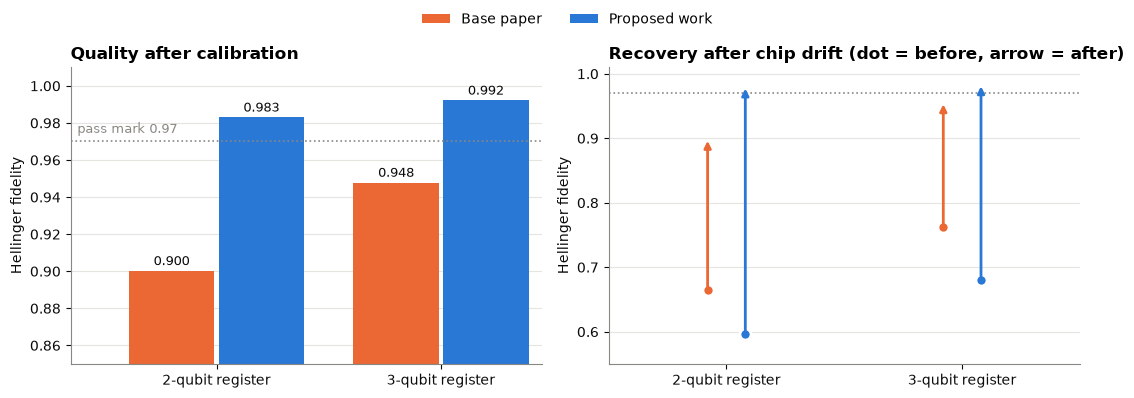

In [7]:
THRESHOLD = 0.97
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
regs = ["2q", "3q"]
x = np.arange(len(regs))
w = 0.38

ax = axes[0]
bf = [base_r["registers"][n]["fidelity_vs_ideal"] for n in regs]
pf = [prop_r["registers"][n]["fidelity_vs_ideal"] for n in regs]
bb = ax.bar(x - w / 2 - 0.01, bf, w, color=BASE_COLOR, label="Base paper")
pb = ax.bar(x + w / 2 + 0.01, pf, w, color=PROP_COLOR, label="Proposed work")
for bars in (bb, pb):
    ax.bar_label(bars, fmt="%.3f", padding=2, fontsize=9, color=INK)
ax.axhline(THRESHOLD, color=MUTED, ls=":", lw=1.2)
ax.text(-0.62, THRESHOLD + 0.003, "pass mark 0.97", ha="left", va="bottom", fontsize=9, color=MUTED)
ax.set_xlim(-0.65, 1.45)
ax.set_ylim(0.85, 1.01)
ax.set_xticks(x)
ax.set_xticklabels(["2-qubit register", "3-qubit register"])
ax.set_ylabel("Hellinger fidelity")
ax.set_title("Quality after calibration", loc="left", fontweight="bold")
ax.grid(axis="x", visible=False)

ax = axes[1]
for i, n in enumerate(regs):
    for r, color, dx in ((base_r, BASE_COLOR, -0.08), (prop_r, PROP_COLOR, 0.08)):
        d = r["registers"][n]["drift"]
        ax.annotate("", xy=(i + dx, d["fidelity_after"]), xytext=(i + dx, d["fidelity_before"]),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=2))
        ax.plot(i + dx, d["fidelity_before"], "o", color=color, ms=8, mec="white", mew=2)
ax.axhline(THRESHOLD, color=MUTED, ls=":", lw=1.2)
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(0.55, 1.01)
ax.set_xticks(x)
ax.set_xticklabels(["2-qubit register", "3-qubit register"])
ax.set_ylabel("Hellinger fidelity")
ax.set_title("Recovery after chip drift (dot = before, arrow = after)", loc="left", fontweight="bold")
ax.grid(axis="x", visible=False)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.savefig(os.path.join(FIG, "fidelity_and_drift.png"), dpi=150)
plt.show()

In [8]:
bc, pc = runs_shots(base_t, ["Stage 6"])[0], runs_shots(prop_t, ["Stage 6"])[0]
bd, pd_ = runs_shots(base_t, ["Drift event"])[0], runs_shots(prop_t, ["Drift event"])[0]
print("SUMMARY")
print(f"  Total wall-clock time  : base {base_t['total_seconds']:.1f} s   proposed {prop_t['total_seconds']:.1f} s")
print(f"  Calibration time       : base {B['Stage 6']['seconds']:.1f} s   proposed {P['Stage 6']['seconds']:.1f} s")
print(f"  Calibration runs       : base {bc}   proposed {pc}   ({1 - pc / bc:.0%} fewer)")
print(f"  Drift recovery runs    : base {bd}   proposed {pd_}   ({1 - pd_ / bd:.0%} fewer)")
for n in ("2q", "3q"):
    b, p = base_r["registers"][n], prop_r["registers"][n]
    print(f"  {n} fidelity            : base {b['fidelity_vs_ideal']:.3f}   proposed {p['fidelity_vs_ideal']:.3f} ({p['decision']})")
    print(f"  {n} after drift         : base {b['drift']['fidelity_after']:.3f}   proposed {p['drift']['fidelity_after']:.3f}")

SUMMARY
  Total wall-clock time  : base 11.6 s   proposed 11.5 s
  Calibration time       : base 5.2 s   proposed 4.5 s
  Calibration runs       : base 824   proposed 408   (50% fewer)
  Drift recovery runs    : base 828   proposed 448   (46% fewer)
  2q fidelity            : base 0.900   proposed 0.983 (ACCEPT)
  2q after drift         : base 0.900   proposed 0.982
  3q fidelity            : base 0.948   proposed 0.992 (ACCEPT)
  3q after drift         : base 0.957   proposed 0.985
